# Derivatives Valuation Toolkit — worked examples

This notebook walks through the `dvt` package: option pricing and Greeks, tree and Monte Carlo cross-checks, forwards and FX hedging, and interest rate swap valuation.

**All inputs below are illustrative assumptions chosen to show the mechanics. They are not market data and not investment advice.**

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path('..', 'src').resolve()))
import numpy as np
import matplotlib.pyplot as plt
import dvt

IMG = pathlib.Path('..', 'docs', 'img'); IMG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 10})
NAVY, TEAL, GOLD, GREY = '#1B355E', '#0F7C8A', '#B8860B', '#8A8F98'

## 1. Black-Scholes pricing

Reference case from Hull (*Options, Futures, and Other Derivatives*, Example 15.6): S = 42, K = 40, r = 10%, σ = 20%, T = 0.5 years. The textbook answers are a call of about 4.76 and a put of about 0.81.

In [2]:
S, K, T, r, sigma = 42, 40, 0.5, 0.10, 0.20
call = dvt.black_scholes(S, K, T, r, sigma, 'call')
put = dvt.black_scholes(S, K, T, r, sigma, 'put')
print(f'Call {call:.4f}   Put {put:.4f}')
print(f'Put-call parity check: C - P = {call - put:.6f}  vs  S - K e^(-rT) = {S - K*np.exp(-r*T):.6f}')

Call 4.7594   Put 0.8086
Put-call parity check: C - P = 3.950823  vs  S - K e^(-rT) = 3.950823


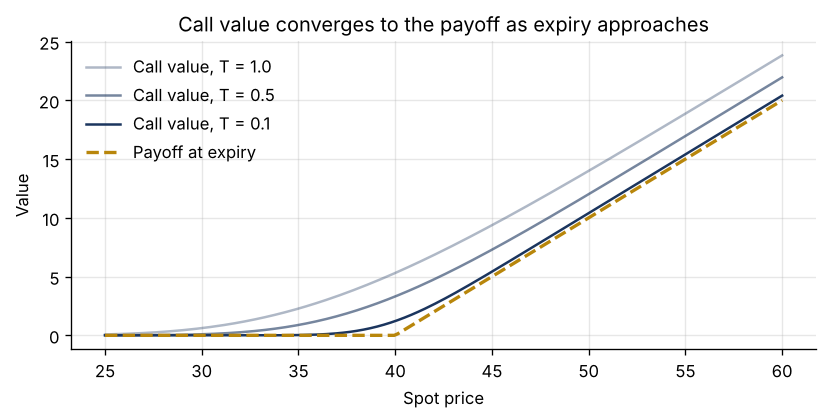

In [3]:
spots = np.linspace(25, 60, 200)
fig, ax = plt.subplots(figsize=(7, 3.6))
for T_, alpha in [(1.0, 0.35), (0.5, 0.6), (0.1, 1.0)]:
    ax.plot(spots, [dvt.black_scholes(s, K, T_, r, sigma, 'call') for s in spots], color=NAVY, alpha=alpha, label=f'Call value, T = {T_}')
ax.plot(spots, np.maximum(spots - K, 0), color=GOLD, lw=2, ls='--', label='Payoff at expiry')
ax.set(xlabel='Spot price', ylabel='Value', title='Call value converges to the payoff as expiry approaches')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(IMG / 'call_value.png'); plt.show()

## 2. Greeks

Analytical Greeks are checked against finite differences in the test suite. Gamma peaks near the strike, which is where delta hedges need the most frequent rebalancing.

Delta 0.7791 | Gamma 0.0500 | Vega per vol pt 0.0881 | Theta per day -0.0125 | Rho per 1% 0.1398


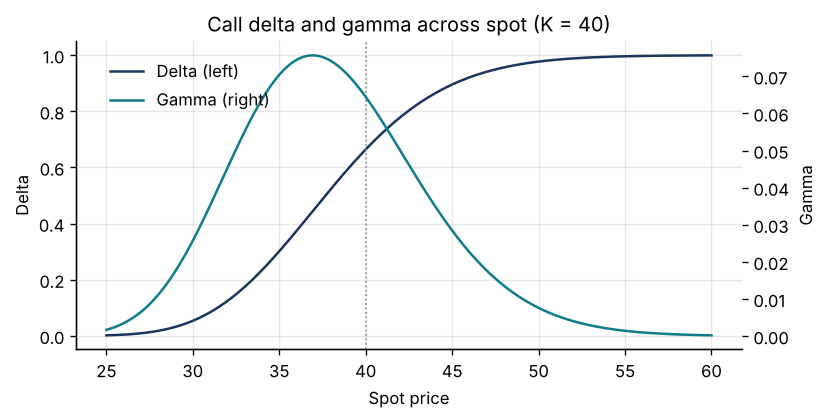

In [4]:
g = dvt.greeks(S, K, T, r, sigma, 'call')
print(f'Delta {g.delta:.4f} | Gamma {g.gamma:.4f} | Vega per vol pt {g.vega/100:.4f} | Theta per day {g.theta/365:.4f} | Rho per 1% {g.rho/100:.4f}')
fig, ax1 = plt.subplots(figsize=(7, 3.6))
d = [dvt.greeks(s, K, T, r, sigma, 'call').delta for s in spots]
gm = [dvt.greeks(s, K, T, r, sigma, 'call').gamma for s in spots]
ax1.plot(spots, d, color=NAVY, label='Delta (left)')
ax2 = ax1.twinx(); ax2.plot(spots, gm, color=TEAL, label='Gamma (right)'); ax2.grid(False)
ax1.axvline(K, color=GREY, ls=':', lw=1)
ax1.set(xlabel='Spot price', ylabel='Delta', title='Call delta and gamma across spot (K = 40)'); ax2.set_ylabel('Gamma')
fig.legend(loc='upper left', bbox_to_anchor=(0.12, 0.88), frameon=False); fig.tight_layout(); fig.savefig(IMG / 'greeks.png'); plt.show()

## 3. Cross-checking the model: binomial tree and Monte Carlo

Three independent methods should agree on a European option. The CRR tree oscillates around the closed form and converges as steps increase; the tree also prices the early-exercise premium of an American put.

Black-Scholes 0.8086 | Monte Carlo 0.8124 (±0.0057) | American put (tree) 0.9104 -> early-exercise premium 0.1018


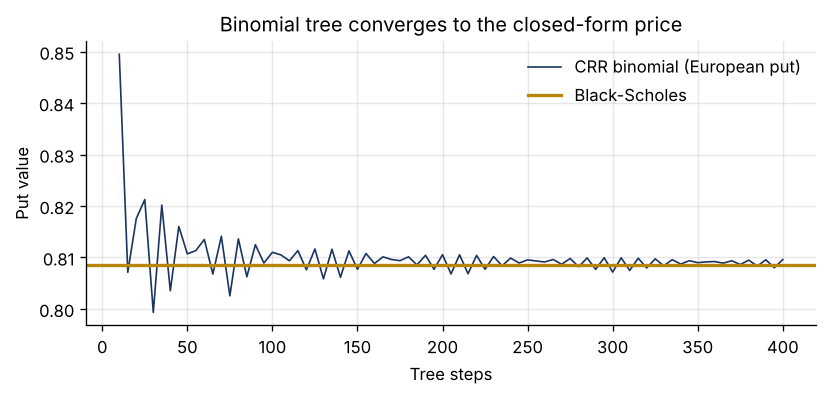

In [5]:
bs_put = dvt.black_scholes(S, K, T, r, sigma, 'put')
steps = np.arange(10, 401, 5)
tree = [dvt.binomial_crr(S, K, T, r, sigma, 'put', steps=int(n)) for n in steps]
mc, se = dvt.monte_carlo(S, K, T, r, sigma, 'put', paths=400_000)
am = dvt.binomial_crr(S, K, T, r, sigma, 'put', steps=1000, american=True)
print(f'Black-Scholes {bs_put:.4f} | Monte Carlo {mc:.4f} (±{1.96*se:.4f}) | American put (tree) {am:.4f} -> early-exercise premium {am-bs_put:.4f}')
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(steps, tree, color=NAVY, lw=1, label='CRR binomial (European put)')
ax.axhline(bs_put, color=GOLD, lw=2, label='Black-Scholes')
ax.set(xlabel='Tree steps', ylabel='Put value', title='Binomial tree converges to the closed-form price')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(IMG / 'convergence.png'); plt.show()

## 4. Implied volatility

Given a market price, solve for the volatility that reproduces it. Here a price is generated at 31% volatility and the solver recovers it.

In [6]:
px = dvt.black_scholes(100, 110, 1.0, 0.02, 0.31, 'call')
print(f'Price {px:.4f} -> implied vol {dvt.implied_volatility(px, 100, 110, 1.0, 0.02, "call"):.6f}')

Price 9.2613 -> implied vol 0.310000


## 5. Forwards: cost of carry for a commodity

For gold, the forward price reflects the funding rate, storage and insurance cost, and the gold lease rate (a convenience yield): F = S·e^{(r + u − y)T}. The spot is normalised to 100, so the chart reads as a percentage premium over spot.

 0.08y  forward 100.305   basis  0.305   implied carry 3.6500%
 0.25y  forward 100.917   basis  0.917   implied carry 3.6500%
 0.50y  forward 101.842   basis  1.842   implied carry 3.6500%
 1.00y  forward 103.717   basis  3.717   implied carry 3.6500%
 2.00y  forward 107.573   basis  7.573   implied carry 3.6500%
 3.00y  forward 111.572   basis 11.572   implied carry 3.6500%


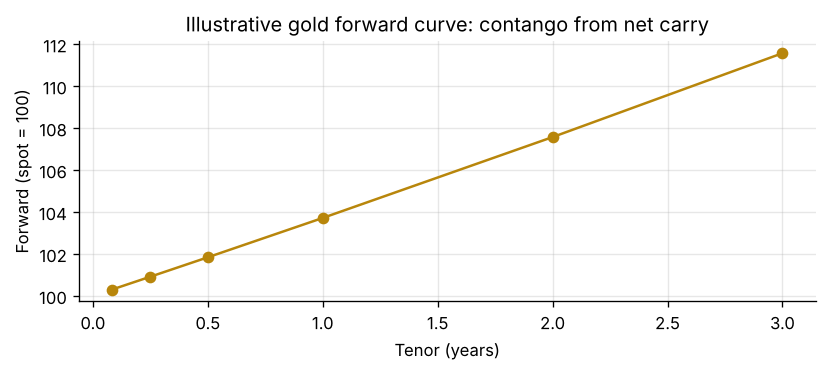

In [7]:
spot, r_usd, lease, storage = 100.0, 0.040, 0.005, 0.0015   # illustrative assumptions
tenors = np.array([1/12, 3/12, 6/12, 1, 2, 3])
curve = [dvt.forward_price(spot, t, r_usd, carry_yield=lease, storage_cost=storage) for t in tenors]
for t, f in zip(tenors, curve):
    print(f'{t:5.2f}y  forward {f:7.3f}   basis {dvt.basis(spot, f):6.3f}   implied carry {dvt.implied_carry(spot, f, t):.4%}')
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(tenors, curve, marker='o', color=GOLD)
ax.set(xlabel='Tenor (years)', ylabel='Forward (spot = 100)', title='Illustrative gold forward curve: contango from net carry')
fig.tight_layout(); fig.savefig(IMG / 'forward_curve.png'); plt.show()

## 6. FX forward hedging

A company expects to convert a USD 10 million receivable into CNH in six months. Covered interest parity sets the forward rate from spot and the two interest rates. The chart compares the CNH proceeds with no hedge, a full hedge and an 80% hedge across possible spot outcomes.

6M forward 7.0132  (-868 pips)


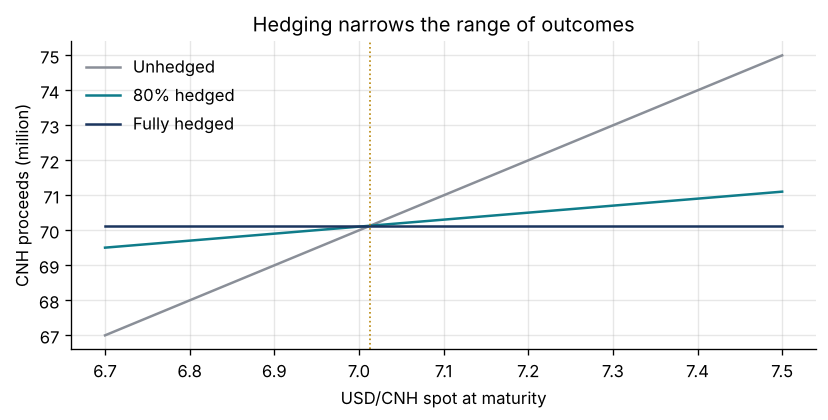

In [8]:
spot_fx, r_cnh, r_usd = 7.10, 0.020, 0.045                 # illustrative assumptions
T_fx, exposure = 0.5, 10_000_000
fwd = dvt.fx_forward(spot_fx, T_fx, r_quote=r_cnh, r_base=r_usd, simple=True)
print(f'6M forward {fwd:.4f}  ({dvt.forward_points(spot_fx, fwd):.0f} pips)')
outcomes = np.linspace(6.70, 7.50, 81)
fig, ax = plt.subplots(figsize=(7, 3.6))
for ratio, colour, label in [(0, GREY, 'Unhedged'), (0.8, TEAL, '80% hedged'), (1.0, NAVY, 'Fully hedged')]:
    proceeds = [dvt.hedge_outcome(exposure, s, fwd, ratio)['hedged'] / 1e6 for s in outcomes]
    ax.plot(outcomes, proceeds, color=colour, label=label)
ax.axvline(fwd, color=GOLD, ls=':', lw=1)
ax.set(xlabel='USD/CNH spot at maturity', ylabel='CNH proceeds (million)', title='Hedging narrows the range of outcomes')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(IMG / 'fx_hedge.png'); plt.show()

## 7. Interest rate swaps

Bootstrap discount factors from a par swap curve, value a 5-year swap and measure its DV01 (value change for a 1bp parallel rise). The curve below is an illustrative upward-sloping curve.

1y  par 3.000%  DF 0.970874  zero 3.0000%
2y  par 3.200%  DF 0.938888  zero 3.2032%
3y  par 3.400%  DF 0.904321  zero 3.4092%
4y  par 3.500%  DF 0.871021  zero 3.5125%
5y  par 3.600%  DF 0.837197  zero 3.6178%
Receive 3.40% fixed vs par 3.60%: value -90,446  DV01 -4,495 per bp


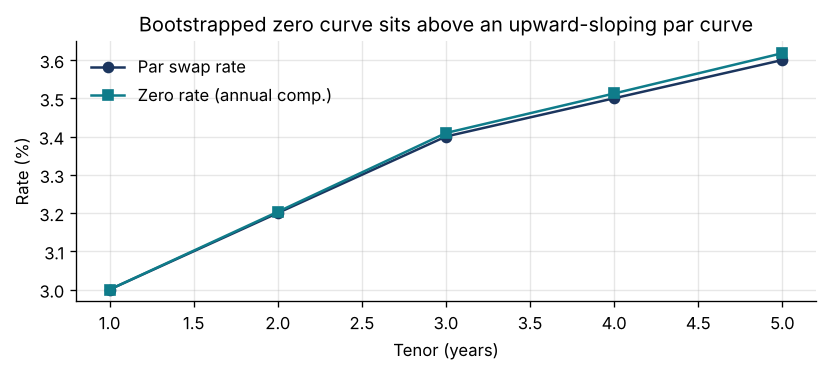

In [9]:
par = {1: 0.030, 2: 0.032, 3: 0.034, 4: 0.035, 5: 0.036}   # illustrative assumptions
dfs = dvt.bootstrap_discount_factors(par)
zeros = {n: dvt.zero_rate(dfs, n, compounding='annual') for n in par}   # same compounding as the par rates
for n in par:
    print(f'{n}y  par {par[n]:.3%}  DF {dfs[n]:.6f}  zero {zeros[n]:.4%}')
v = dvt.value_swap(10_000_000, 0.034, 5, par, receive_fixed=True)
print(f'Receive 3.40% fixed vs par 3.60%: value {v.value:,.0f}  DV01 {v.dv01:,.0f} per bp')
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(list(par), [x*100 for x in par.values()], marker='o', color=NAVY, label='Par swap rate')
ax.plot(list(zeros), [x*100 for x in zeros.values()], marker='s', color=TEAL, label='Zero rate (annual comp.)')
ax.set(xlabel='Tenor (years)', ylabel='Rate (%)', title='Bootstrapped zero curve sits above an upward-sloping par curve')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(IMG / 'swap_curve.png'); plt.show()